# Dados do Recife e o modelo SEIR-SEI

**Leandro Cesar**
Elementos de Epidemiologia Computacional, BSI UFRPE

Este notebook reúne os resultados preliminares da proposta de projeto. Ele parte das lacunas do SIR
(notebook 01) e faz quatro coisas: organiza a série de casos de chikungunya do Recife, mede o que ela diz
sobre a transmissão, implementa o modelo com mosquito e período de latência sugerido pela professora,
comparando-o com o SIR, e confronta os dois modelos com a onda de 2021 e com os registros da época.

| Seção | Conteúdo |
| --- | --- |
| 1 | Os dados do portal da Prefeitura do Recife |
| 2 | A taxa de crescimento observada e o R0 que cada modelo exige |
| 3 | O modelo SEIR-SEI e seus parâmetros |
| 4 | SIR e SEIR-SEI lado a lado |
| 5 | Controle vetorial com o mosquito explícito |
| 6 | A segunda onda e os registros da época |
| 7 | O que fica para a proposta |

In [1]:
source("../R/load_all.R")
tamanho_figura()

## 1. Os dados

O portal de dados abertos da Prefeitura do Recife publica, no conjunto *Casos de Dengue, Zika e
Chikungunya*, um arquivo por ano com as notificações de chikungunya de 2015 a 2025. Apesar do nome
"casos confirmados", cada arquivo traz todas as notificações, com a classificação final de cada uma:
confirmada, descartada ou inconclusiva. Os arquivos também trazem endereço e data de nascimento. Por isso
o script `scripts/baixar_dados.R` guarda os arquivos brutos em `data/raw/`, fora do controle de versão, e
só a série agregada por semana entra no repositório.

Decisões de tratamento, todas em `R/dados.R`:

- **Data.** A semana é a de início dos sintomas, identificada pelo domingo em que começa. Quando a data
  de sintomas falta ou é incoerente com a data de notificação, vale a de notificação.
- **Duplicidade.** Registros com o mesmo número e a mesma data de notificação aparecem uma vez só.
- **Caso provável.** Segue a definição do Ministério da Saúde: toda notificação, exceto as descartadas
  (código 5 da classificação final).
- **Códigos antigos.** Em 2015 e até meados de 2016 aparecem os códigos 1 e 2 na classificação final, que
  não constam no dicionário do portal. Eles não foram tratados como descartados e entram como prováveis.
  Isso é uma limitação dos dados, registrada aqui para ser esclarecida com a vigilância.

In [2]:
serie <- le_serie_semanal()
anual <- aggregate(cbind(notificados, provaveis, confirmados) ~ format(semana, "%Y"),
                   data = serie, FUN = sum)
names(anual)[1] <- "ano"
anual

ano,notificados,provaveis,confirmados
<chr>,<int>,<int>,<int>
2015,1723,1266,175
2016,11218,8723,4920
2017,1114,553,552
2018,667,355,336
2019,1454,784,780
2020,2850,2242,2181
2021,17862,16013,16012
2022,1911,1101,1098
2023,1548,598,596


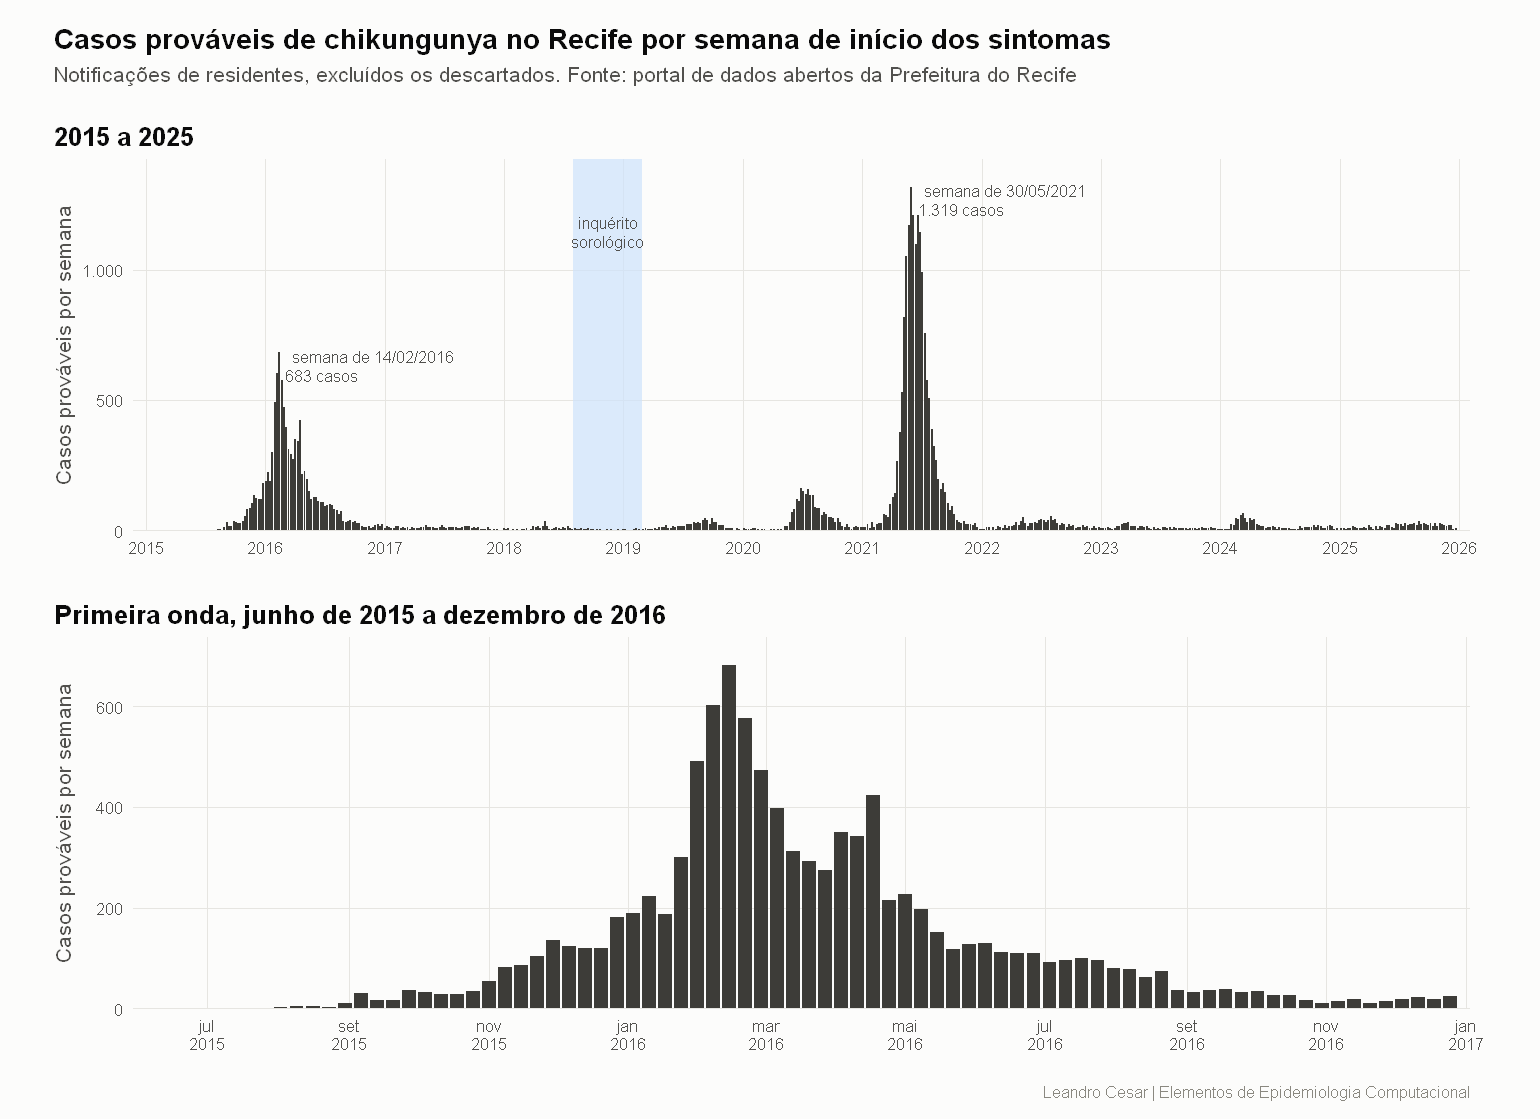

In [3]:
tamanho_figura(11, 8)
figura_dados_recife(serie)

A série tem duas ondas grandes. A primeira começa em agosto de 2015 e tem pico na semana de 14 de
fevereiro de 2016, com 683 casos prováveis. A segunda, em 2021, é maior nas notificações, com pico na
semana de 30 de maio e 1.319 casos. Entre as duas, a transmissão continua baixa. A faixa azul marca o
período do inquérito sorológico de Braga et al. (2023), feito antes da segunda onda.

## 2. O que a taxa de crescimento diz

No começo de um surto, quando quase todos ainda são suscetíveis, os casos crescem de forma exponencial, e
a taxa de crescimento $r$ aparece como a inclinação da reta numa escala logarítmica. A taxa observada no
Recife foi medida por regressão linear do logaritmo dos casos prováveis semanais, de 30 de agosto de 2015 a
31 de janeiro de 2016.

In [4]:
cresc <- crescimento_observado(serie)
r0s <- r0_pela_taxa(cresc$r)
data.frame(
  `r por dia` = num_br(cresc$r, 4),
  `IC 95 por cento` = paste(num_br(cresc$r_inf, 4), "a", num_br(cresc$r_sup, 4)),
  `Duplicação em dias` = num_br(log(2) / cresc$r, 1),
  `R0 exigido pelo SIR` = num_br(r0s[["SIR"]], 2),
  `R0 exigido pelo SEIR-SEI` = num_br(r0s[["SEIR-SEI"]], 2),
  check.names = FALSE
)

r por dia,IC 95 por cento,Duplicação em dias,R0 exigido pelo SIR,R0 exigido pelo SEIR-SEI
<chr>,<chr>,<chr>,<chr>,<chr>
"0,0208","0,0183 a 0,0232","33,4","1,12","1,71"


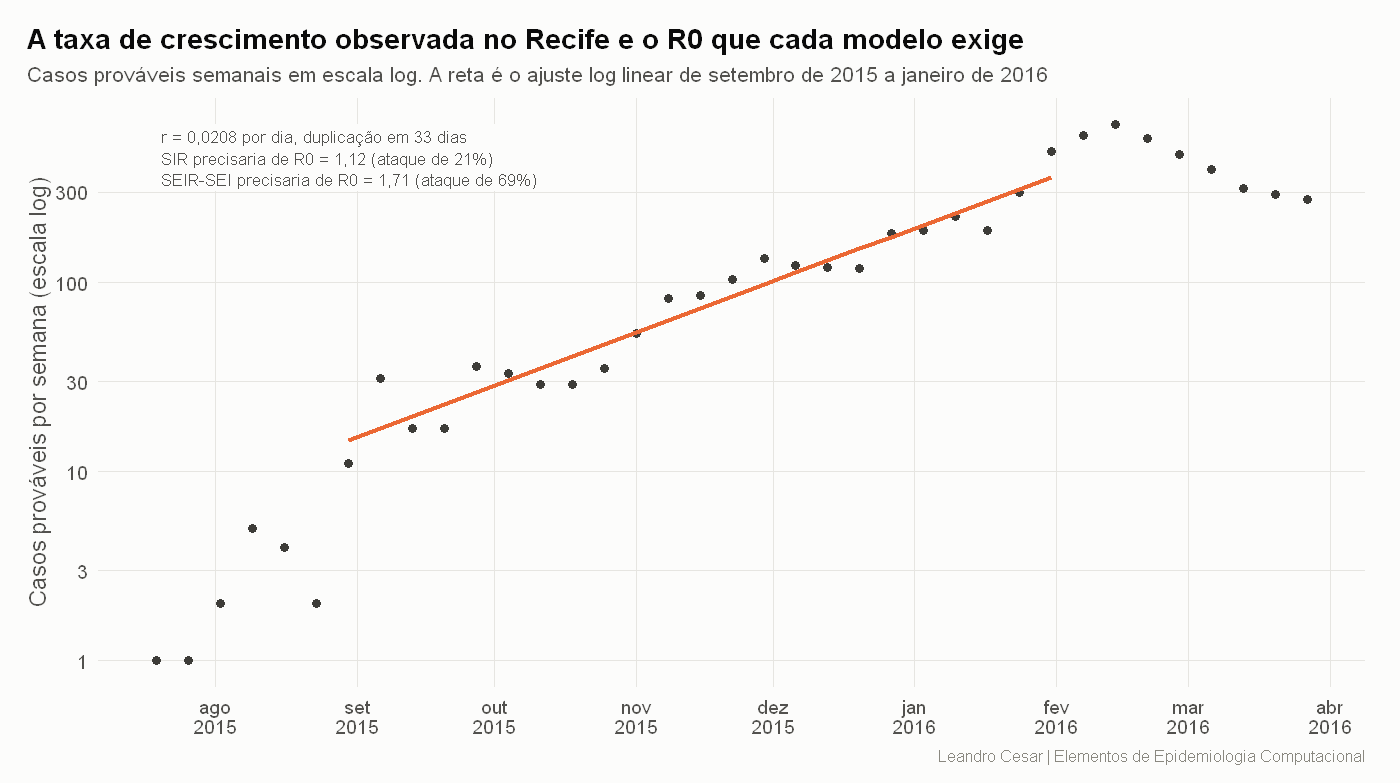

In [5]:
tamanho_figura(10, 5.6)
figura_crescimento(serie, cresc, r0s)

Os casos cresceram 2,1 por cento ao dia, dobrando a cada 33 dias. O mesmo número pede R0 diferentes
conforme o modelo, porque cada modelo tem um intervalo de geração diferente.

- **No SIR**, $r = \gamma (R_0 - 1)$, então $R_0 = 1 + r/\gamma = 1{,}12$. Com esse R0, só 21 por cento da
  cidade se infectaria.
- **No SEIR-SEI** da seção 3, cada geração demora muito mais, porque inclui a latência humana, a
  incubação no mosquito e a vida do mosquito. Para crescer à mesma taxa, o modelo precisa de um número de
  reprodução de humano para humano de 1,71, e a taxa de ataque seria de 69 por cento.

Junto com a literatura e o inquérito, são quatro estimativas:

| Origem | R0 de humano para humano | Taxa de ataque |
| --- | --- | --- |
| Literatura (Haider et al., 2020) | 3,40 | 96 por cento |
| Crescimento observado, lido pelo SEIR-SEI | 1,71 | 69 por cento |
| Inquérito sorológico (Braga et al., 2023) | 1,24 | 36 por cento |
| Crescimento observado, lido pelo SIR | 1,12 | 21 por cento |

Nenhum modelo homogêneo reproduz ao mesmo tempo a velocidade e o tamanho da primeira onda. O SEIR-SEI,
lido pelo crescimento, chega mais perto do inquérito do que o SIR com o R0 da literatura, mas ainda
superestima o tamanho. A diferença que sobra é o que a proposta pretende explicar com sazonalidade,
heterogeneidade entre grupos e fração de notificação. Há também uma ressalva sobre os dados: parte do
crescimento das notificações pode vir do aumento da atenção dos serviços à doença nova, e não só da
transmissão.

## 3. O modelo SEIR-SEI

O modelo acrescenta ao SIR as duas coisas que a professora sugeriu: o período de latência nos humanos e o
mosquito como população explícita.

**Humanos**, população $N_h$ fechada: $S_h \to E_h \to I_h \to R_h$.

**Mosquitos** *Aedes aegypti*, população $N_v = m N_h$: $S_v \to E_v \to I_v$. Os mosquitos nascem e
morrem na taxa $\mu_v$, e o mosquito infectado transmite até morrer.

Na notação de Ross e Macdonald (Smith et al., 2012), $a$ é o número de picadas por mosquito por dia, $b$ a
probabilidade de a picada de um mosquito infectante infectar o humano e $c$ a probabilidade de um humano
infectado infectar o mosquito que o pica.

$$\frac{dS_h}{dt} = -a b \frac{I_v}{N_h} S_h \qquad
\frac{dE_h}{dt} = a b \frac{I_v}{N_h} S_h - \sigma_h E_h \qquad
\frac{dI_h}{dt} = \sigma_h E_h - \gamma I_h \qquad
\frac{dR_h}{dt} = \gamma I_h$$

$$\frac{dS_v}{dt} = \mu_v N_v - a c \frac{I_h}{N_h} S_v - \mu_v S_v \qquad
\frac{dE_v}{dt} = a c \frac{I_h}{N_h} S_v - (\sigma_v + \mu_v) E_v \qquad
\frac{dI_v}{dt} = \sigma_v E_v - \mu_v I_v$$

In [6]:
cat(readLines("../R/seir_sei_model.R"), sep = "\n")

# Modelo SEIR-SEI da proposta: humanos com período de latência e o mosquito
# Aedes aegypti como compartimentos explícitos.
#
# Humanos: Sh -> Eh -> Ih -> Rh, população fechada.
# Mosquitos: Sv -> Ev -> Iv, com nascimento e morte na taxa mu_v. O mosquito
# infectado permanece infectante até morrer.
#
# Notação de Ross e Macdonald (Smith et al., 2012): a picadas por mosquito por
# dia, b a probabilidade de o mosquito infectar o humano na picada, c a de o
# humano infectar o mosquito, m mosquitos por humano.

ROTULOS_SEIR <- c(Sh = "Suscetíveis", Eh = "Expostos", Ih = "Infectados", Rh = "Recuperados")

# Humanos infectados por um mosquito recém infectado: ele sobrevive à incubação
# com probabilidade sigma_v / (sigma_v + mu_v) e depois pica por 1 / mu_v dias.
r_vetor_para_humano <- function(p) {
  p[["a"]] * p[["b"]] * p[["sigma_v"]] / ((p[["sigma_v"]] + p[["mu_v"]]) * p[["mu_v"]])
}

# Mosquitos infectados por um humano durante o período infeccioso de 1 / gamma dias.
r_humano_para_vetor

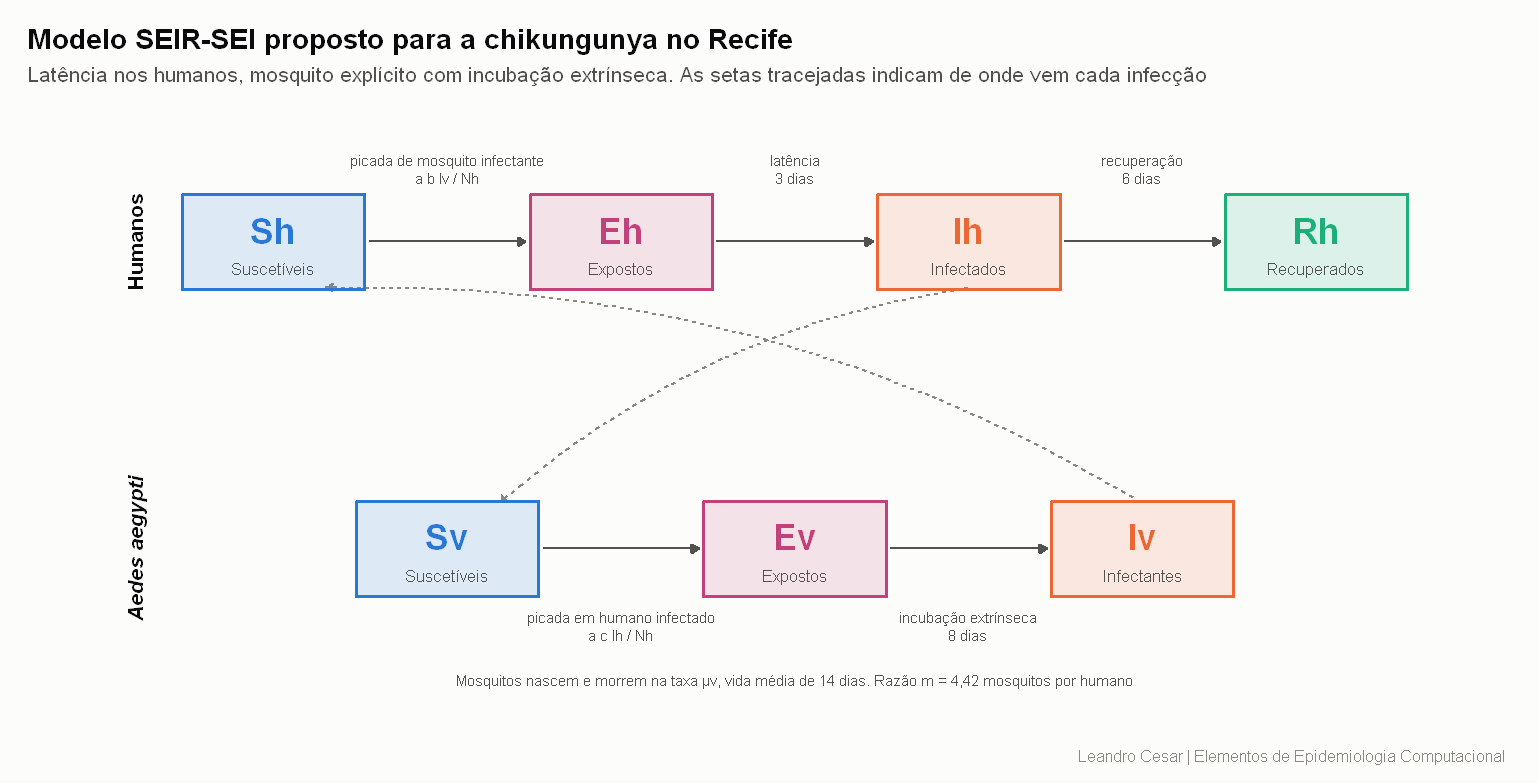

In [7]:
tamanho_figura(11, 5.6)
p <- parametros_vetor()
figura_diagrama_seir_sei(p)

### Parâmetros

Os valores vêm de Manore et al. (2014), que reúnem parâmetros de chikungunya para o *Aedes aegypti*, com
duas exceções. A latência humana de 3 dias coincide com a mediana da revisão de Rudolph et al. (2014). A
incubação extrínseca de 8 dias é a média estimada por Christofferson et al. (2014) para a linhagem ECSA,
a que circulou no Nordeste. Eles recomendam usar a média, e não o tempo mais curto em que o vírus aparece
na saliva do mosquito, porque o tempo mais curto superestima a velocidade da epidemia.

In [8]:
tabela_p <- read.csv("../results/seir_sei_parametros.csv")
tabela_p$valor <- num_br(tabela_p$valor, 2)
tabela_p

parametro,descricao,valor,fonte
<chr>,<chr>,<chr>,<chr>
a,picadas por mosquito por dia,"0,50",Manore et al. 2014
b,prob. mosquito infectar humano,"0,24",Manore et al. 2014
c,prob. humano infectar mosquito,"0,24",Manore et al. 2014
1/sigma_h,latência humana (dias),"3,00",Manore et al. 2014; Rudolph et al. 2014
1/gamma,período infeccioso humano (dias),"6,00",Manore et al. 2014
1/sigma_v,incubação extrínseca (dias),"8,00",Christofferson et al. 2014
1/mu_v,vida média do mosquito (dias),"14,00",Manore et al. 2014
m,mosquitos por humano,"4,42","escolhido para R0 de humano para humano = 3,4"


### O número de reprodução

Uma volta completa da transmissão tem duas metades.

- Um humano infectado é picado por $a m$ mosquitos por dia durante $1/\gamma$ dias e infecta, em média,
  $R_{vh} = a c m / \gamma$ mosquitos.
- Um mosquito recém infectado sobrevive à incubação com probabilidade $\sigma_v / (\sigma_v + \mu_v)$ e
  depois pica durante $1/\mu_v$ dias, infectando em média $R_{hv} = a b \sigma_v / ((\sigma_v + \mu_v)\mu_v)$
  humanos.

O produto $R_{hv} R_{vh}$ é o número de humanos infectados, em média, por um humano, depois de uma volta
pelo mosquito. É ele que corresponde ao R0 do SIR e que determina o tamanho final do surto. O R0 calculado
pela matriz de próxima geração é a raiz quadrada desse produto, porque conta cada metade como uma
geração (Manore et al., 2014).

Ninguém mede a razão $m$ de mosquitos por humano numa cidade inteira. Por isso $m$ foi escolhido para que o
número de humano para humano seja 3,4, o mesmo do SIR. Assim os dois modelos têm o mesmo tamanho final e
a comparação isola o efeito da latência e do mosquito.

In [9]:
data.frame(
  Grandeza = c("m, mosquitos por humano", "R_vh, mosquitos infectados por um humano",
               "R_hv, humanos infectados por um mosquito",
               "R0 de humano para humano", "R0 de próxima geração"),
  Valor = num_br(c(p[["m"]], r_humano_para_vetor(p), r_vetor_para_humano(p),
                   r_humano_humano(p), r0_vetorial(p)), 3)
)

Grandeza,Valor
<chr>,<chr>
"m, mosquitos por humano","4,417"
"R_vh, mosquitos infectados por um humano","3,180"
"R_hv, humanos infectados por um mosquito","1,069"
R0 de humano para humano,"3,400"
R0 de próxima geração,"1,844"


## 4. SIR e SEIR-SEI lado a lado

In [10]:
comp <- comparacao_sir_vetorial(duracao = 400)
modelos <- read.csv("../results/modelos_resumo.csv")
data.frame(
  Modelo = modelos$modelo,
  `R0 humano` = num_br(modelos$R0_humano, 2),
  `Crescimento inicial por dia` = num_br(modelos$crescimento_inicial, 4),
  `Dia do pico` = modelos$dia_pico,
  `Infectados no pico` = milhares(modelos$I_pico),
  `Taxa de ataque` = paste0(num_br(100 * modelos$taxa_ataque, 1), " por cento"),
  check.names = FALSE
)

Modelo,R0 humano,Crescimento inicial por dia,Dia do pico,Infectados no pico,Taxa de ataque
<chr>,<chr>,<chr>,<int>,<chr>,<chr>
SIR,"3,40","0,4000",38,515.090,"96,2 por cento"
SEIR-SEI,"3,40","0,0533",271,115.189,"94,9 por cento"


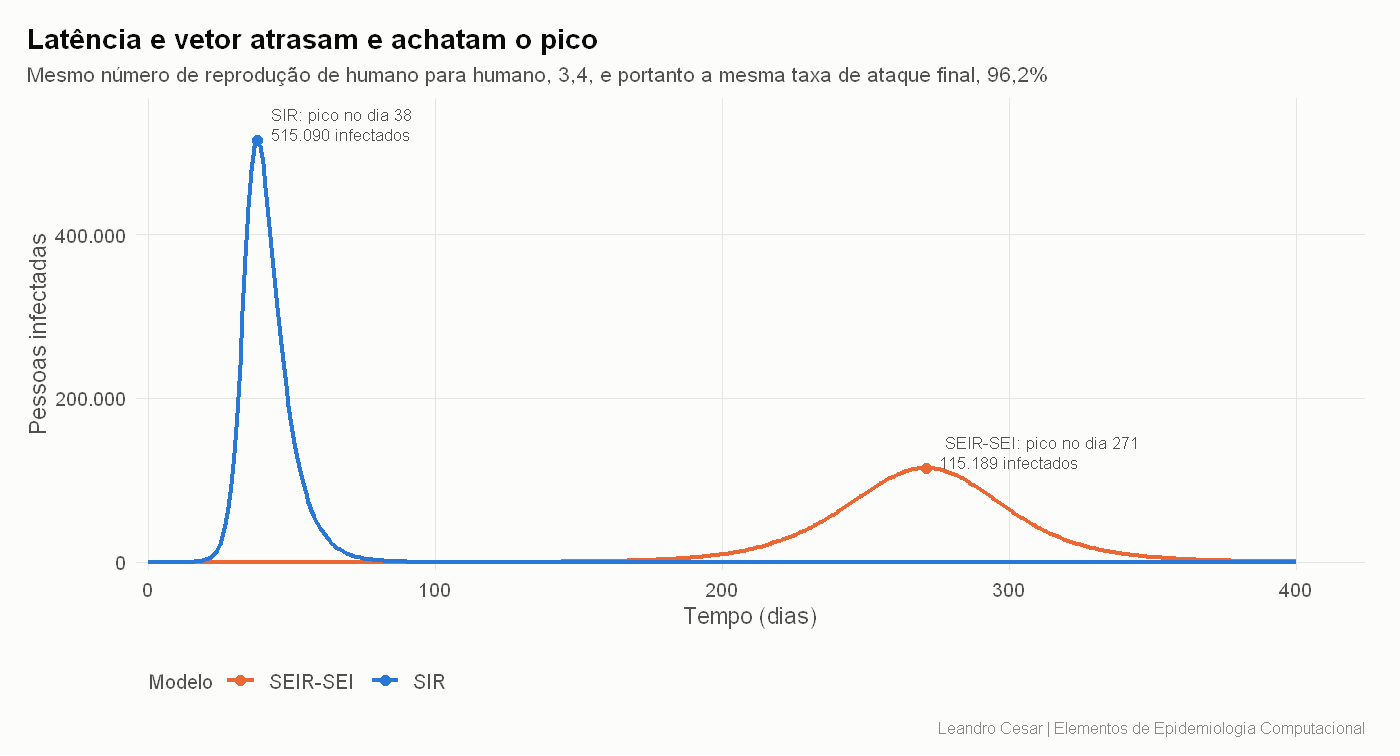

In [11]:
tamanho_figura(10, 5.4)
figura_sir_vs_vetorial(comp)

Com o mesmo número de reprodução, o SEIR-SEI cresce a 0,053 por dia em vez de 0,40, e o pico passa do dia
38 para o dia 271, cerca de nove meses depois do primeiro caso. O pico também fica quatro vezes e meia mais
baixo, porque a mesma quantidade de infecções se espalha por um tempo muito maior. A ordem de grandeza do
tempo até o pico fica parecida com a do Recife, onde a primeira onda levou uns seis meses entre o início
do crescimento e o pico. O SIR erra esse tempo por um fator de cerca de cinco.

**Conferências.** O script de renderização confere quatro coisas no SEIR-SEI:

1. As populações de humanos e de mosquitos ficam constantes.
2. A taxa de crescimento da simulação, 0,0534 por dia, bate com o maior autovalor da matriz do sistema
   linearizado, 0,0533 por dia.
3. Com número de reprodução 0,9 não há surto.
4. O tamanho final, 94,9 por cento, fica um pouco abaixo dos 96,2 por cento da equação
   $1 - a = e^{-R_0 a}$. A equação supõe que quase todos os mosquitos continuam suscetíveis, mas no pico
   cerca de um décimo deles está infectado, o que reduz um pouco a transmissão.

## 5. Controle vetorial com o mosquito explícito

No SIR, o controle só podia ser uma redução de β, aplicada de uma vez (notebook 01, seção 5.4). No
SEIR-SEI, o controle de criadouros reduz o nascimento de mosquitos, e a população adulta só diminui à
medida que os mosquitos existentes morrem, ao longo da vida média de 14 dias.

Como o número de reprodução de humano para humano é proporcional a $m$, a redução de criadouros que
impede o surto é a mesma do SIR, $1 - 1/3{,}4 = 70{,}6$ por cento. Esse é um ponto em que a definição de R0
importa. Quem usasse o R0 de próxima geração, 1,84, calcularia $1 - 1/1{,}84 = 46$ por cento e
subestimaria o esforço necessário.

A figura usa uma redução de 80 por cento, acima da eficácia crítica, começando em três momentos da fase de
crescimento.

In [12]:
ctrl <- controle_vetorial()
with(ctrl$resumo, data.frame(
  Rodada = serie,
  `Dia do pico` = dia_pico,
  `Infectados no pico` = milhares(I_pico),
  `Taxa de ataque` = paste0(num_br(100 * taxa_ataque, 1), " por cento"),
  `Crescimento nas 2 semanas após o início` = ifelse(is.na(crescimento_14_dias), "",
                                                    paste0(num_br(crescimento_14_dias, 2), " vezes")),
  check.names = FALSE
))

Rodada,Dia do pico,Infectados no pico,Taxa de ataque,Crescimento nas 2 semanas após o início
<chr>,<dbl>,<chr>,<chr>,<chr>
Sem controle,271,115.189,"95,0 por cento",
Início no dia 120,160,410,"0,6 por cento","1,95 vezes"
Início no dia 200,233,23.936,"25,5 por cento","1,87 vezes"
Início no dia 250,264,105.579,"76,2 por cento","1,25 vezes"


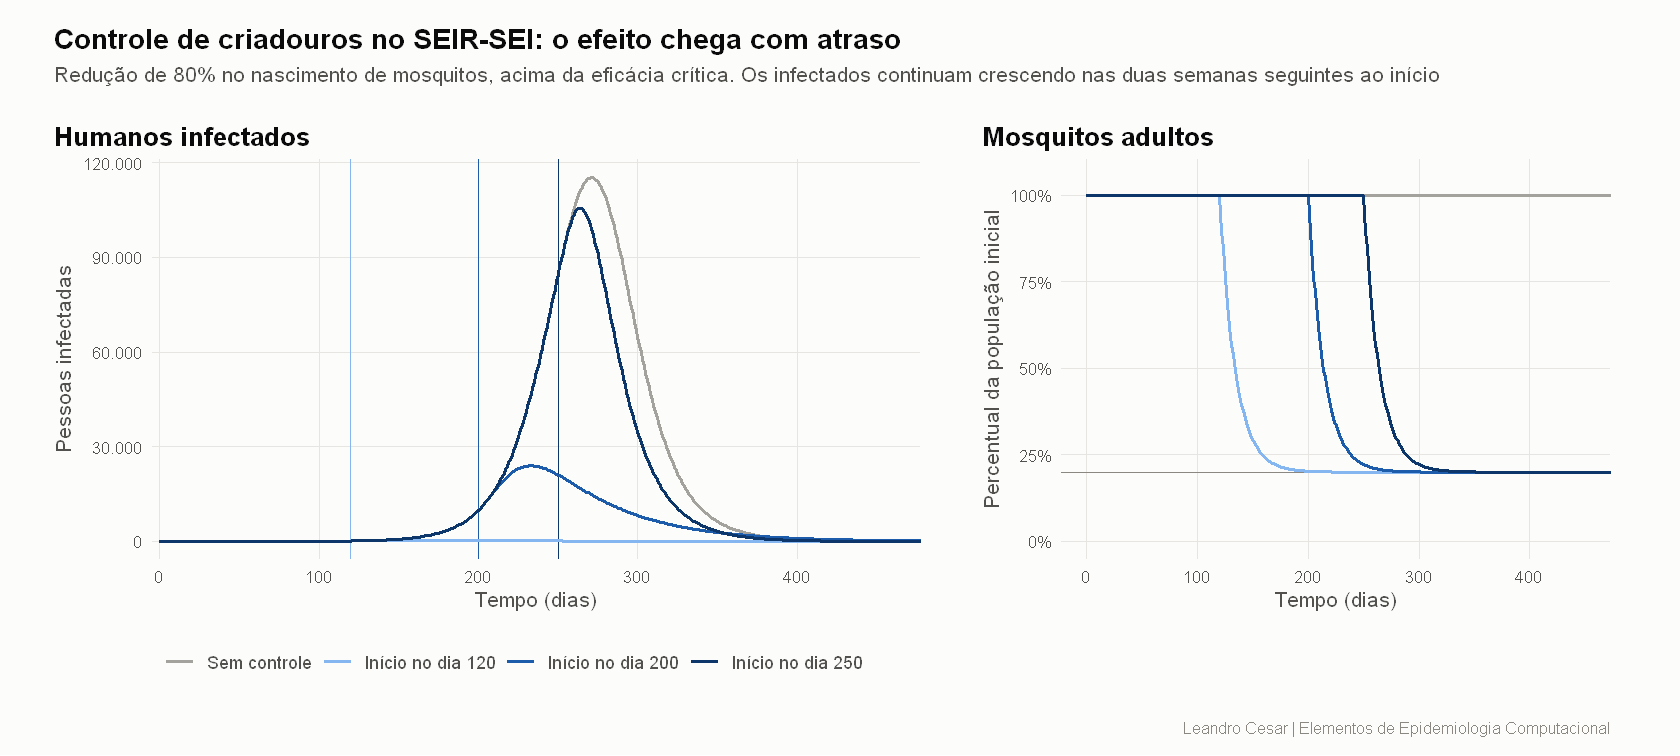

In [13]:
tamanho_figura(12, 5.4)
figura_controle_vetorial(ctrl)

Começando no dia 120, o controle deixa a taxa de ataque em 0,6 por cento. No dia 200, em 25 por cento. No
dia 250, poucas semanas antes do pico, em 76 por cento. Em todos os casos os infectados ainda crescem nas
duas semanas seguintes ao início, porque os mosquitos já infectados continuam picando até morrer. O
resultado é o mesmo do SIR, agir cedo vale mais, só que agora com o atraso que vem da biologia do
mosquito.

## 6. A segunda onda e os registros da época

Os arquivos do portal trazem mais do que a data dos sintomas: o critério de confirmação, a evolução do
caso, a hospitalização, a idade e o distrito. A tabela resume esses campos para os casos prováveis de cada
ano.

In [14]:
anual <- read.csv("../data/processed/chik_recife_ano.csv")
por_cento <- function(x) paste0(num_br(100 * x, 0), " por cento")
with(anual, data.frame(
  Ano = ano,
  `Casos prováveis` = milhares(provaveis),
  `Confirmados em laboratório` = por_cento(criterio_laboratorio / provaveis),
  `Óbitos pelo agravo` = obitos,
  `Hospitalização informada` = por_cento(hospitalizacao_informada / provaveis),
  `Idade mediana` = idade_mediana,
  check.names = FALSE
))

Ano,Casos prováveis,Confirmados em laboratório,Óbitos pelo agravo,Hospitalização informada,Idade mediana
<int>,<chr>,<chr>,<int>,<chr>,<dbl>
2015,1.215,14 por cento,4,4 por cento,41.0
2016,8.774,7 por cento,53,23 por cento,36.0
2017,546,9 por cento,2,58 por cento,35.5
2018,359,16 por cento,2,43 por cento,36.0
2019,786,33 por cento,2,58 por cento,35.0
2020,2.240,15 por cento,0,44 por cento,39.0
2021,16.014,7 por cento,1,56 por cento,38.0
2022,1.103,12 por cento,0,71 por cento,34.0
2023,596,9 por cento,2,73 por cento,32.0


Em 2015 e 2016, 92 por cento dos casos prováveis foram encerrados pelo critério clínico epidemiológico,
sem confirmação em laboratório. Foram 57 óbitos pelo agravo, com mediana de 68 anos em 2016, e o campo de
hospitalização veio preenchido em só 21 por cento dos casos. Esses números explicam por que mortes e
hospitalizações entram na proposta como desfechos calculados, e não como compartimentos.

Os números do portal batem com os que a Prefeitura divulgava na época. Em novembro de 2021, a CBN Recife
noticiou as notificações de 2021 feitas até 26 de outubro. Refeita a contagem no mesmo recorte:

In [15]:
boletim <- read.csv("../data/processed/chik_recife_boletim_2021.csv")
data.frame(
  Fonte = c("Prefeitura, divulgado em 17/11/2021", "Portal hoje, mesmo recorte"),
  Notificados = milhares(c(BOLETIM_2021$notificados, boletim$notificados)),
  `Casos prováveis` = milhares(c(BOLETIM_2021$provaveis, boletim$provaveis)),
  check.names = FALSE
)

Fonte,Notificados,Casos prováveis
<chr>,<chr>,<chr>
"Prefeitura, divulgado em 17/11/2021",16.026,14.926
"Portal hoje, mesmo recorte",16.645,15.058


A diferença, de 3,9 e 0,9 por cento, é compatível com notificações registradas depois do boletim.

### As duas ondas

A primeira onda cresceu de setembro de 2015 a janeiro de 2016, no período mais seco do Recife, e a de 2021
de março a maio, no início da estação chuvosa. Abril a julho concentram 59,8 por cento da chuva anual da
cidade, e setembro a dezembro, 11,2 por cento (Ferreira, 2016). A mesma regressão log linear da seção 2,
aplicada às duas fases de crescimento:

In [16]:
serie <- le_serie_semanal()
ondas <- comparacao_ondas(serie)
with(ondas, data.frame(
  Onda = onda,
  `Fase de crescimento` = paste(format(inicio, "%d/%m/%Y"), "a", format(fim, "%d/%m/%Y")),
  `Crescimento por dia` = num_br(r, 4),
  `Duplicação em dias` = num_br(duplicacao_dias, 0),
  `Suscetíveis, no máximo` = por_cento(suscetiveis_max),
  `R efetivo no SEIR-SEI` = num_br(R_efetivo_SEIR_SEI, 2),
  `R0 implícito no SEIR-SEI` = num_br(R0_SEIR_SEI, 2),
  check.names = FALSE
))

Onda,Fase de crescimento,Crescimento por dia,Duplicação em dias,"Suscetíveis, no máximo",R efetivo no SEIR-SEI,R0 implícito no SEIR-SEI
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2015 e 2016,30/08/2015 a 31/01/2016,"0,0208",33,100 por cento,"1,71","1,71"
2021,28/02/2021 a 16/05/2021,"0,0458",15,64 por cento,"2,93","4,56"


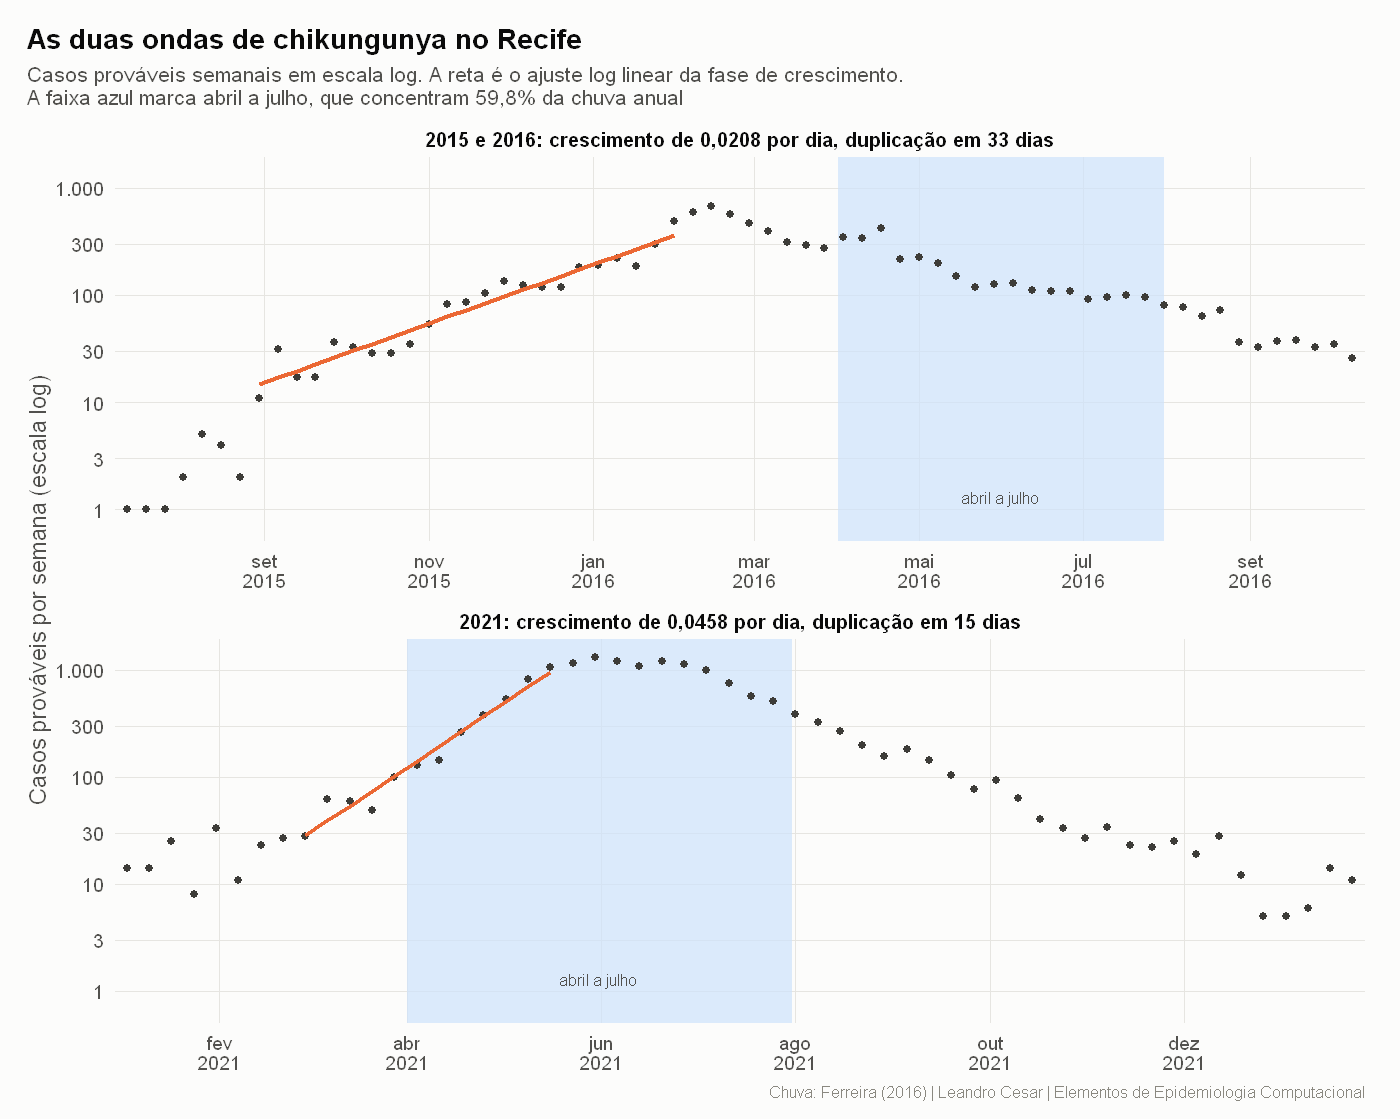

In [17]:
tamanho_figura(10, 8)
figura_duas_ondas(serie, ondas)

A onda de 2021 cresceu 2,2 vezes mais rápido, e os intervalos de confiança não se sobrepõem. Com os
parâmetros fixos, um modelo homogêneo prevê o contrário: com menos suscetíveis, a segunda onda deveria
crescer mais devagar. Lida pelo SEIR-SEI, a onda de 2021 exige $R_{hh}$ de pelo menos 4,56, contra 1,71 na
primeira. O vírus e a cidade são os mesmos, então as condições de transmissão mudaram entre as ondas. A
estação é a primeira candidata, e a notificação, que em 2015 disputava atenção com o zika e em 2021 com a
covid-19, é a segunda.

### Os distritos

Se a cidade se misturasse por igual, cada distrito teria em 2021 a mesma proporção de casos em relação à
primeira onda.

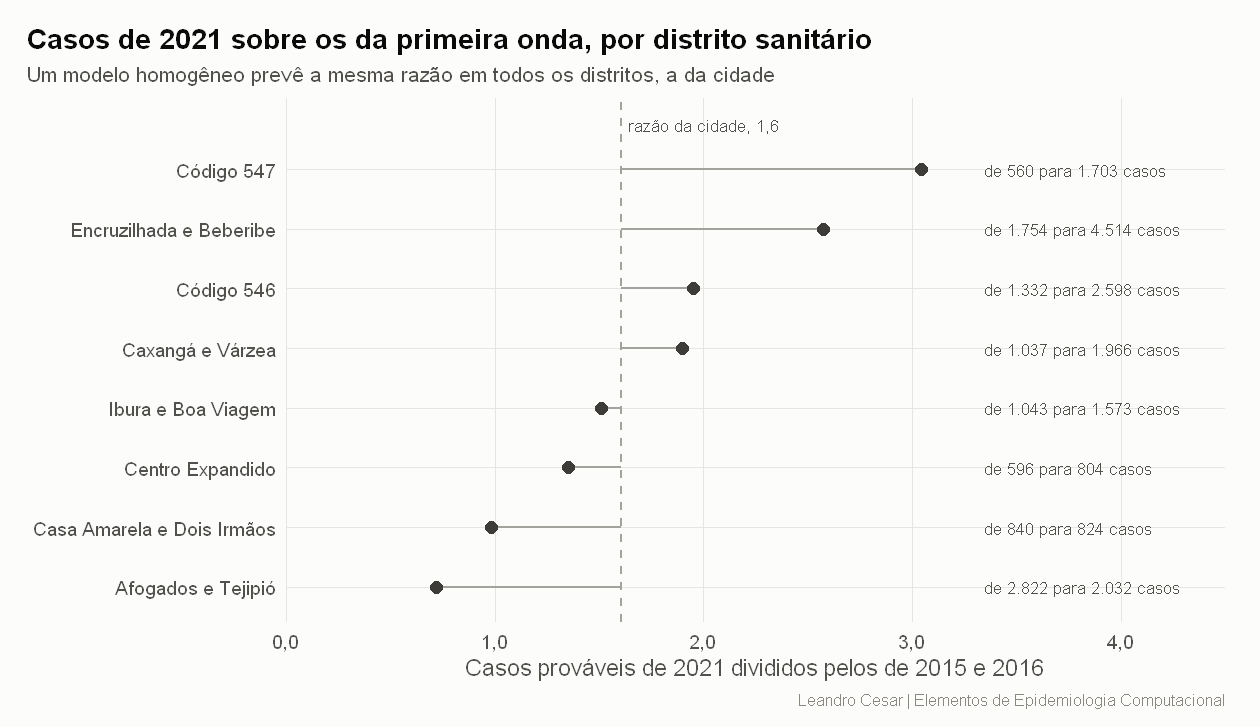

In [18]:
distritos <- comparacao_distritos(le_distrito_ano())
tamanho_figura(9, 5.2)
figura_distritos(distritos)

A razão variou de 0,72 a 3,04, contra 1,6 da cidade. Afogados e Tejipió, o distrito com mais casos na
primeira onda, teve menos casos em 2021 do que em 2015 e 2016. A comparação ainda não considera a
população de cada distrito nem a mudança nos códigos 546 e 547, que não constam na tabela do portal.

### Quantos pontos divergem

A tabela reúne o que os dois modelos homogêneos preveem, com $R_{hh} = 3{,}4$, e o que se observou. Ela é
gravada pelo `render_figures.R`.

In [19]:
comparacao <- read.csv("../results/modelo_contra_dados.csv")
comparacao[, -1] <- lapply(comparacao[, -1], function(x)
  ifelse(is.na(x), "", formatC(x, format = "fg", digits = 3, decimal.mark = ",")))
comparacao

ponto,SIR,SEIR_SEI,observado
<chr>,<chr>,<chr>,<chr>
taxa de ataque,"0,962","0,949","0,357"
crescimento da primeira onda por dia,"0,4","0,0533","0,0208"
dias até o pico,38,271,217
R efetivo ao fim da primeira onda,"0,129","0,173",
crescimento da segunda onda sobre o da primeira,"0,494","0,595","2,2"
"razão 2021 sobre a primeira onda, menor distrito","1,6","1,6","0,72"
"razão 2021 sobre a primeira onda, maior distrito","1,6","1,6","3,04"
infecções por caso provável,,,"53,2"
óbitos pelo agravo na primeira onda,,,57


Somando a reinfecção, que os dois modelos excluem e que a onda de 2021 não exige, são nove pontos. O SIR
diverge dos dados em seis e o SEIR-SEI em cinco. O SEIR-SEI aproxima o tempo até o pico, os dois coincidem
na imunidade duradoura, e notificação e óbitos estão fora de ambos.

## 7. O que fica para a proposta

Estes resultados preliminares definem os objetivos da proposta:

1. **Calibrar o SEIR-SEI com a série do Recife**, estimando o número de reprodução e a fração de
   notificação, com o inquérito sorológico como restrição para o tamanho final.
2. **Incluir a sazonalidade**, fazendo a densidade de mosquitos variar ao longo do ano, e testá-la pela
   capacidade de reproduzir também o crescimento mais rápido da onda de 2021.
3. **Representar a heterogeneidade**, separando a população em grupos, por distrito sanitário ou por
   estrato socioeconômico, como no inquérito, e conferir se o modelo reproduz a mudança na distribuição
   dos casos entre os distritos.
4. **Avaliar cenários de controle vetorial** com o modelo calibrado, variando a eficácia e o momento de
   início.

## Referências

- BRAGA, C. et al. Seroprevalence of Dengue, Chikungunya and Zika at the epicenter of the congenital
  microcephaly epidemic in Northeast Brazil: a population-based survey. *PLoS Neglected Tropical
  Diseases*, v. 17, n. 7, e0011270, 2023.
- BRITO, C. A. A.; TEIXEIRA, M. G. Increased number of deaths during a chikungunya epidemic in
  Pernambuco, Brazil. *Memórias do Instituto Oswaldo Cruz*, v. 112, n. 9, 2017.
- CHRISTOFFERSON, R. C. et al. Chikungunya viral fitness measures within the vector and subsequent
  transmission potential. *PLoS ONE*, v. 9, n. 10, e110538, 2014.
- FERREIRA, F. F. Climatologia da precipitação na cidade do Recife. In: CONGRESSO TÉCNICO CIENTÍFICO DA
  ENGENHARIA E DA AGRONOMIA, CONTECC 2016, Foz do Iguaçu, 2016.
- HAIDER, N. et al. Basic reproduction number of chikungunya virus transmitted by *Aedes* mosquitoes.
  *Emerging Infectious Diseases*, v. 26, n. 10, p. 2429 a 2431, 2020.
- MANORE, C. A. et al. Comparing dengue and chikungunya emergence and endemic transmission in *A. aegypti*
  and *A. albopictus*. *Journal of Theoretical Biology*, v. 356, p. 174 a 191, 2014.
- PREFEITURA DO RECIFE. *Casos de Dengue, Zika e Chikungunya*. Portal de Dados Abertos do Recife.
  Disponível em https://dados.recife.pe.gov.br/dataset/casos-de-dengue-zika-e-chikungunya.
- RECIFE ultrapassa 18 mil casos de dengue e chikungunya. CBN Recife, 17 nov. 2021. Disponível em
  https://acervo.cbnrecife.com/artigo/recife-ultrapassa-18-mil-casos-de-dengue-e-chikungunya.
- RUDOLPH, K. E. et al. Incubation periods of mosquito-borne viral infections: a systematic review.
  *American Journal of Tropical Medicine and Hygiene*, v. 90, n. 5, p. 882 a 891, 2014.
- SMITH, D. L. et al. Ross, Macdonald, and a theory for the dynamics and control of mosquito-transmitted
  pathogens. *PLoS Pathogens*, v. 8, n. 4, e1002588, 2012.